# Predição de valor de imóvel usando a rede MLP.

---

Este exemplo utiliza a base de dados California_Housing.


## Etapa 01
Importar as bibliotecas de aprendizado de máquina e computação científica.


In [1]:
#Bibliotecas de aprendizado de máquina
from tensorflow import keras
from keras.models import Sequential
from keras.layers import Dense, Dropout

from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler

#Bibliotecas de computação científica
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd


## Etapa 02
Importar a base de dados California Housing do keras

Curiosidade: o Keras fornece um conjunto de base de dados para aprendizado. Veja mais em: https://keras.io/api/datasets/


In [2]:
(x_train, y_train), (x_test, y_test) = keras.datasets.california_housing.load_data()

## Etapa 03
Conhecer e plotar a base de dados


In [3]:
#Verificar a quantidade de dados para treinamento e validação
print('x_train', x_train.shape)
print('y_train', y_train.shape)
print('x_test', x_test.shape)
print('y_test', y_test.shape)


x_train (16512, 8)
y_train (16512,)
x_test (4128, 8)
y_test (4128,)


In [4]:
x_train[0,:]

array([-118.27  ,   34.09  ,   52.    , 2327.    ,  555.    , 1048.    ,
        491.    ,    3.7847], dtype=float32)

In [5]:
y_train

array([252300., 146900., 290900., ..., 500001., 499000., 238100.],
      dtype=float32)

### Visualização de Outliers com Boxplot

Análise da distribuição das variáveis preditoras e do valor alvo (`MedianHouseValue`) para identificar a presença de valores atípicos (outliers) utilizando boxplots individuais e padronizados.


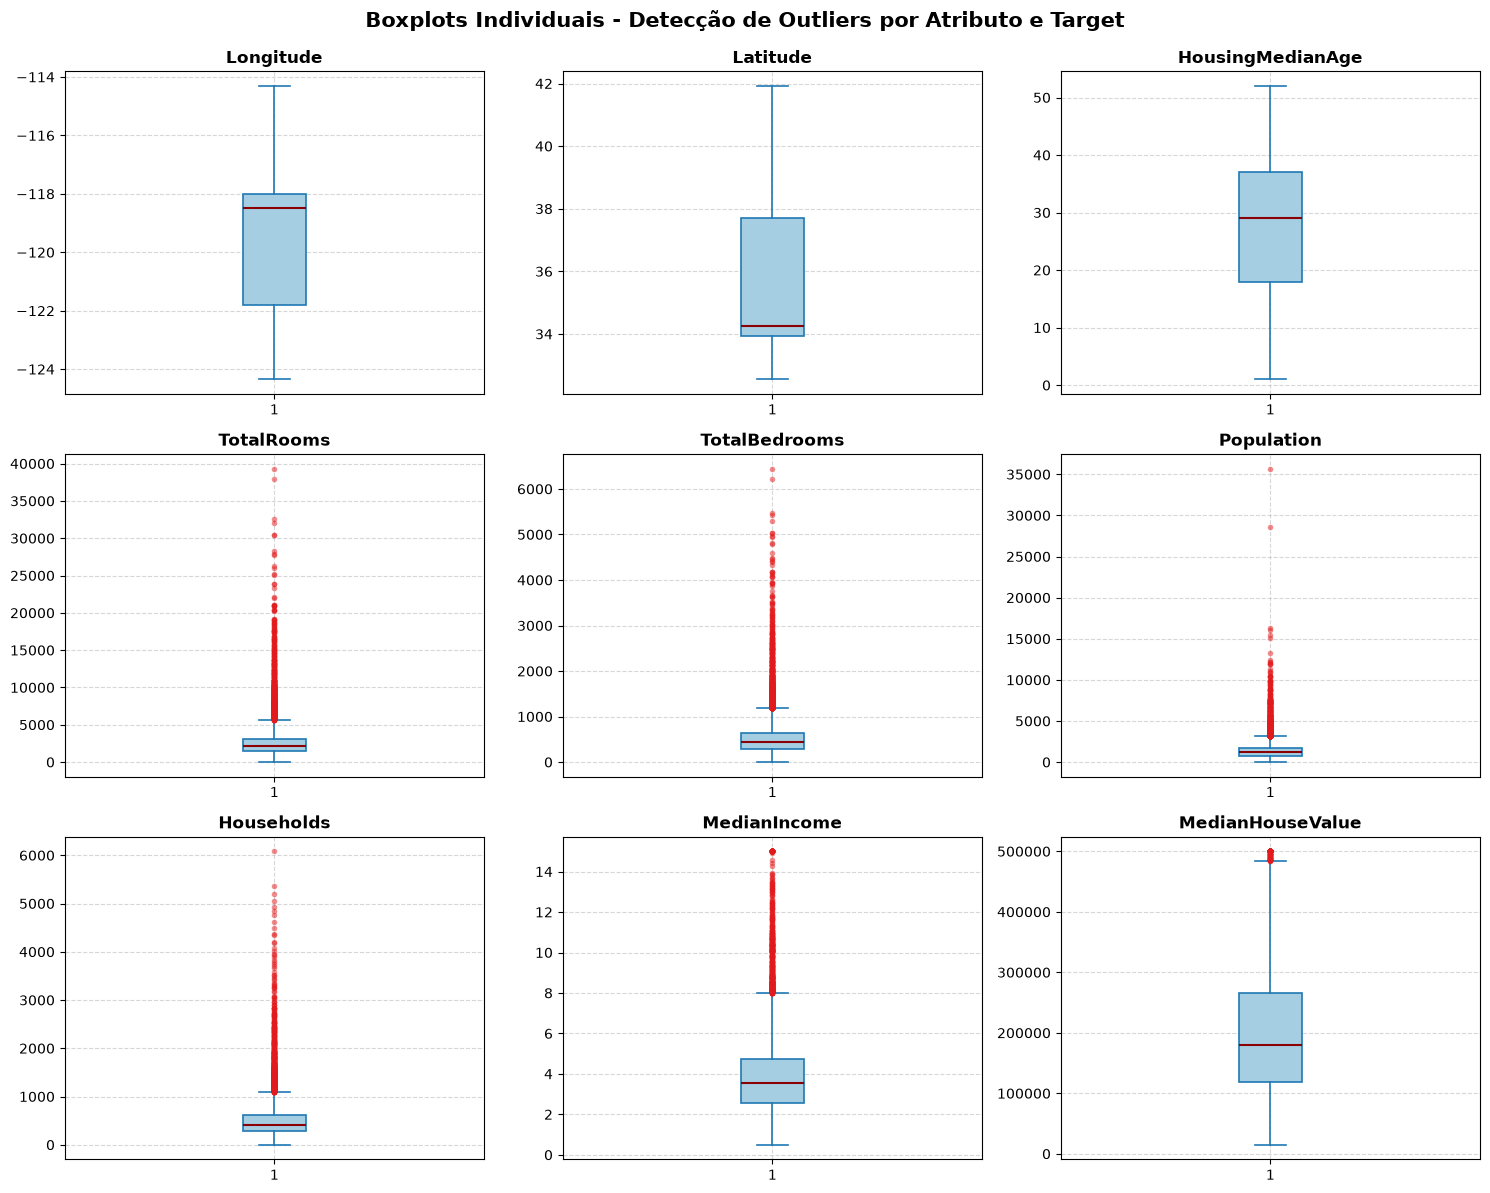

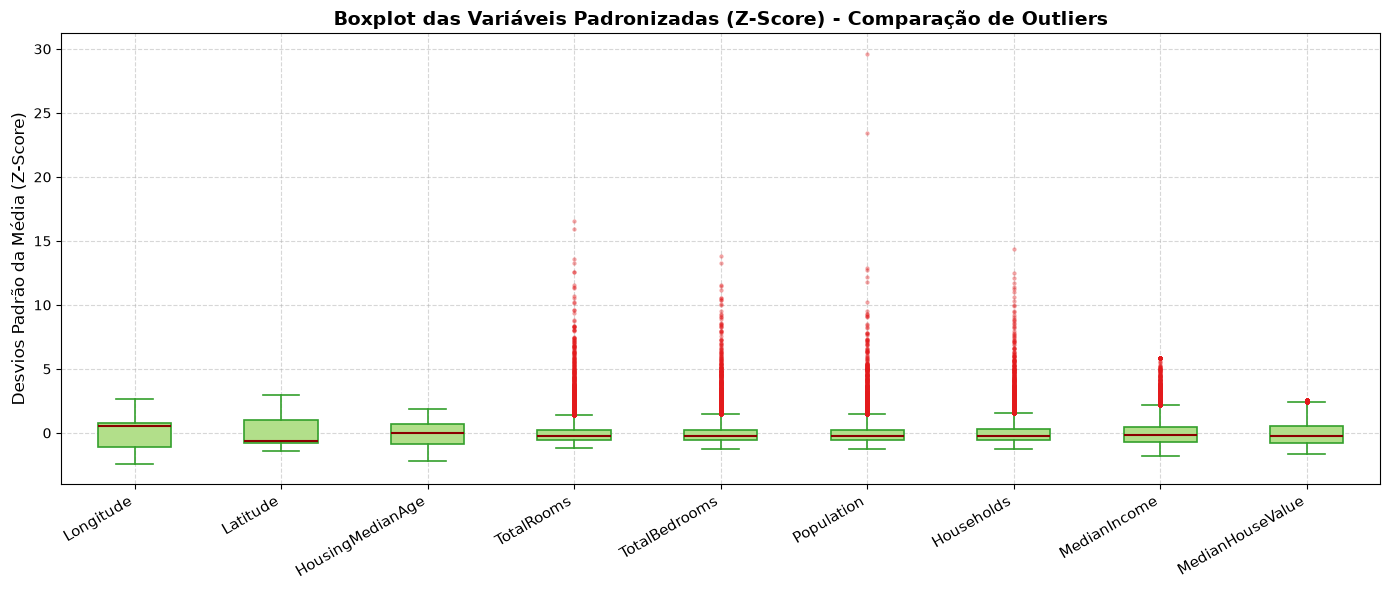

=== Resumo Estatístico de Outliers (Método IQR: 1.5 * IQR) ===
        Atributo  Q1 (25%)   Mediana  Q3 (75%)  Limite Sup  Qtd Outliers % Outliers
       Longitude   -121.79   -118.49   -118.00     -112.31             0      0.00%
        Latitude     33.93     34.25     37.71       43.38             0      0.00%
HousingMedianAge     18.00     29.00     37.00       65.50             0      0.00%
      TotalRooms   1451.00   2133.50   3145.25     5686.62          1053      6.38%
   TotalBedrooms    295.00    436.00    649.00     1180.00          1024      6.20%
      Population    789.00   1172.00   1735.00     3154.00           960      5.81%
      Households    279.00    411.00    607.00     1099.00           972      5.89%
    MedianIncome      2.56      3.54      4.74        8.00           548      3.32%
MedianHouseValue 119100.00 179450.00 265000.00   483850.00           837      5.07%


In [4]:
# Nomes dos atributos do California Housing (StatLib / Pace & Barry)
feature_names = [
    'Longitude', 'Latitude', 'HousingMedianAge', 
    'TotalRooms', 'TotalBedrooms', 'Population', 
    'Households', 'MedianIncome'
]

# Criar DataFrame para exploração estatística
df_train = pd.DataFrame(x_train, columns=feature_names)
df_train['MedianHouseValue'] = y_train

# 1. Boxplots individuais para cada atributo e variável alvo (escala própria)
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()

for i, col in enumerate(df_train.columns):
    axes[i].boxplot(
        df_train[col], 
        patch_artist=True,
        boxprops=dict(facecolor='#a6cee3', color='#1f78b4', linewidth=1.2),
        medianprops=dict(color='darkred', linewidth=1.5),
        whiskerprops=dict(color='#1f78b4', linewidth=1.2),
        capprops=dict(color='#1f78b4', linewidth=1.2),
        flierprops=dict(marker='o', markerfacecolor='#e31a1c', markersize=4, alpha=0.5, markeredgecolor='none')
    )
    axes[i].set_title(col, fontsize=12, fontweight='bold')
    axes[i].grid(True, linestyle='--', alpha=0.5)

plt.suptitle('Boxplots Individuais - Detecção de Outliers por Atributo e Target', fontsize=15, fontweight='bold', y=0.99)
plt.tight_layout()
plt.show()

# 2. Boxplot padronizado (Z-Score) para comparação da dispersão de outliers
scaler_vis = StandardScaler()
df_scaled = pd.DataFrame(scaler_vis.fit_transform(df_train), columns=df_train.columns)

fig, ax = plt.subplots(figsize=(14, 6))
df_scaled.boxplot(
    ax=ax,
    patch_artist=True,
    boxprops=dict(facecolor='#b2df8a', color='#33a02c', linewidth=1.2),
    medianprops=dict(color='darkred', linewidth=1.5),
    whiskerprops=dict(color='#33a02c', linewidth=1.2),
    capprops=dict(color='#33a02c', linewidth=1.2),
    flierprops=dict(marker='o', markerfacecolor='#e31a1c', markersize=3, alpha=0.4, markeredgecolor='none')
)
ax.set_title('Boxplot das Variáveis Padronizadas (Z-Score) - Comparação de Outliers', fontsize=14, fontweight='bold')
ax.set_ylabel('Desvios Padrão da Média (Z-Score)', fontsize=12)
ax.set_xticklabels(df_train.columns, rotation=30, ha='right', fontsize=11)
ax.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# 3. Resumo estatístico e contagem de outliers pelo critério IQR (1.5 * IQR)
print('=== Resumo Estatístico de Outliers (Método IQR: 1.5 * IQR) ===')
outlier_rows = []
for col in df_train.columns:
    q1 = df_train[col].quantile(0.25)
    q3 = df_train[col].quantile(0.75)
    iqr = q3 - q1
    inf = q1 - 1.5 * iqr
    sup = q3 + 1.5 * iqr
    outliers = int(((df_train[col] < inf) | (df_train[col] > sup)).sum())
    pct = (outliers / len(df_train)) * 100
    outlier_rows.append({
        'Atributo': col,
        'Q1 (25%)': round(float(q1), 2),
        'Mediana': round(float(df_train[col].median()), 2),
        'Q3 (75%)': round(float(q3), 2),
        'Limite Sup': round(float(sup), 2),
        'Qtd Outliers': outliers,
        '% Outliers': f'{pct:.2f}%'
    })

df_resumo = pd.DataFrame(outlier_rows)
print(df_resumo.to_string(index=False))


## Etapa 04
Normalizar os atributos e a variável alvo utilizando StandardScaler.


In [6]:
scaler = StandardScaler()
X_trainn = scaler.fit_transform(x_train)
X_testn = scaler.transform(x_test)

y_train = y_train.reshape(-1, 1)
y_trainn = scaler.fit_transform(y_train)
y_test = y_test.reshape(-1, 1)
y_testn = scaler.transform(y_test)

## Etapa 05
Construir a rede neural utilizando o Keras.


In [7]:
keras.backend.clear_session()
model = Sequential()
model.add(Dense(100, input_dim=8, activation='relu')),
model.add(Dropout(0.5)),
model.add(Dense(100, activation='relu')),
model.add(Dense(1, activation='linear'))

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 100)            │           900 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 50)             │         5,050 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,001 (23.44 KB)

 Trainable params: 6,001 (23.44 KB)

 Non-trainable params: 0 (0.00 B)

## Etapa 06
Compilar o modelo.

Optimizer: As opções são encontradas em https://keras.io/api/optimizers/

Loss: As opções são encontradas em https://keras.io/api/losses/

Metrics: As opções são encontradas em https://keras.io/api/metrics/


In [8]:
model.compile(optimizer='Adam',
              loss='mse',
              metrics=['mae'])

## Etapa 07
Treinar o modelo e realizar a validação.


In [9]:
#Parada antecipada
early_stop = keras.callbacks.EarlyStopping(
    monitor='val_mae',
    patience=20,
    min_delta=1e-4,
    restore_best_weights=True
)

Epoch 1/300
516/516 - 5s - 10ms/step - loss: 0.4400 - mae: 0.4917 - val_loss: 0.3284 - val_mae: 0.4166
Epoch 2/300
516/516 - 2s - 3ms/step - loss: 0.3359 - mae: 0.4223 - val_loss: 0.3020 - val_mae: 0.3938
Epoch 3/300
516/516 - 2s - 3ms/step - loss: 0.3160 - mae: 0.4059 - val_loss: 0.2892 - val_mae: 0.3810
Epoch 4/300
516/516 - 2s - 3ms/step - loss: 0.3001 - mae: 0.3955 - val_loss: 0.2811 - val_mae: 0.3785
Epoch 5/300
516/516 - 2s - 3ms/step - loss: 0.2898 - mae: 0.3875 - val_loss: 0.2872 - val_mae: 0.3760
Epoch 6/300
516/516 - 2s - 3ms/step - loss: 0.2845 - mae: 0.3818 - val_loss: 0.2763 - val_mae: 0.3676
Epoch 7/300
516/516 - 2s - 3ms/step - loss: 0.2787 - mae: 0.3775 - val_loss: 0.2734 - val_mae: 0.3617
Epoch 8/300
516/516 - 2s - 3ms/step - loss: 0.2719 - mae: 0.3712 - val_loss: 0.2691 - val_mae: 0.3711
Epoch 9/300
516/516 - 2s - 3ms/step - loss: 0.2669 - mae: 0.3669 - val_loss: 0.2638 - val_mae: 0.3642
Epoch 10/300
516/516 - 2s - 3ms/step - loss: 0.2621 - mae: 0.3636 - val_loss: 0.2

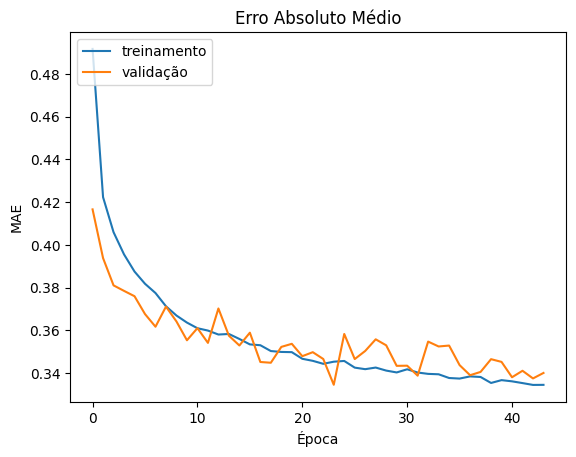

In [10]:
history = model.fit(X_trainn, y_trainn, epochs=300, batch_size=32, validation_data=(X_testn, y_testn), callbacks=[early_stop], verbose=2)
plt.plot(history.history['mae'])
plt.plot(history.history['val_mae'])
plt.title('Erro Absoluto Médio')
plt.ylabel('MAE')
plt.xlabel('Época')
plt.legend(['treinamento', 'validação'], loc='upper left')
plt.show()

## Etapa 08

Verificando os erros das amostras de teste


129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


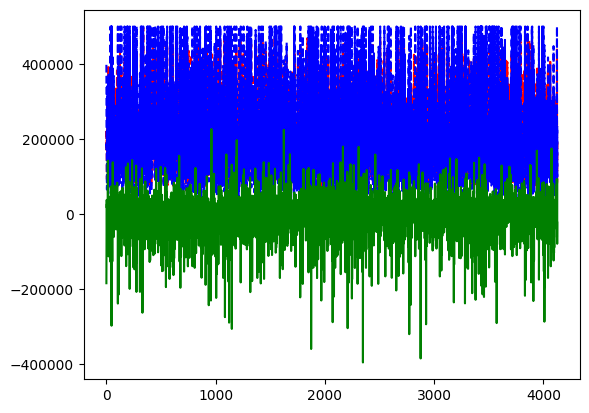

Valor médio do erro -3060.9849


In [11]:
predict_values = model.predict(X_testn)
predict_values = scaler.inverse_transform(predict_values)

plt.plot(predict_values, 'r--')
plt.plot(y_test, 'b--')
plt.plot(predict_values-y_test, 'g')
plt.show(
)

print('Valor médio do erro', np.mean(predict_values-y_test))